# CSET485 – AI and Society · Assignment #1 · COMPAS stress-tests
**Roll number 0450 → last digit 0 → COMPAS Recidivism Risk Score dataset · random seed 450 · 70/30 train–test split.**

This notebook regenerates **every number, table and figure** cited in the PDF report. Running it top-to-bottom
(a) downloads/validates the COMPAS file, (b) preprocesses without leakage, (c) fits Model A (OLS on `decile_score`) and
Model B (logistic regression on `is_recidivist`), (d) runs the four stress tests (Simpson's-paradox hunt,
omitted-variable bias, adversarial subset, fairness trade-off sweep) and (e) writes `results/results.json`,
`results/tables/*.csv` and `results/figures/*.png`, which `src/build_report.py` turns into the PDF.

**Contents** 0 Setup · 1 Data loading & validation · 2 Preprocessing · 3 EDA · 4 Split & scaling · 5 Part 1 models ·
6 Part 1 threshold comparison · 7 Part 2.1 · 8 Part 2.2 · 9 Part 2.3 · 10 Part 2.4 · 11 Robustness · 12 Export & summary

## 0 · Setup

In [1]:
import json, hashlib, platform, sys, urllib.request, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import sklearn, scipy, statsmodels, matplotlib
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             brier_score_loss, log_loss, mean_squared_error, mean_absolute_error, r2_score)
warnings.filterwarnings("ignore")
%matplotlib inline

SEED = 450                      # last three digits of roll number 0450
np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_DIR, RES = ROOT / "data", ROOT / "results"
FIG, TAB = RES / "figures", RES / "tables"
for p in (DATA_DIR, FIG, TAB): p.mkdir(parents=True, exist_ok=True)

R = {}   # every number cited in the PDF is stored here and exported to results/results.json
def save_table(df, name, index=True): df.to_csv(TAB / f"{name}.csv", index=index)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

R["env"] = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "statsmodels": statsmodels.__version__,
            "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}
print(R["env"])

{'python': '3.12.3', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'statsmodels': '0.15.0', 'scipy': '1.17.1', 'matplotlib': '3.10.8'}


## 1 · Dataset loading and validation
The file is downloaded once from the ProPublica repository and cached in `data/`. The SHA-256 hash is recorded so that
anyone re-running the notebook can confirm they analysed the identical file.

In [2]:
URL = "https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv"
csv_path = DATA_DIR / "compas-scores-two-years.csv"
if not csv_path.exists():
    urllib.request.urlretrieve(URL, csv_path)
raw = pd.read_csv(csv_path)
sha = hashlib.sha256(csv_path.read_bytes()).hexdigest()

# ---- validation against the assignment's requirements ----
required = ["sex","age","race","juv_fel_count","juv_misd_count","juv_other_count","priors_count",
            "c_charge_degree","decile_score","is_recid","two_year_recid"]
assert all(c in raw.columns for c in required), "expected COMPAS columns are missing"
assert raw["id"].is_unique
assert raw["decile_score"].between(1, 10).all()
assert set(raw["two_year_recid"].unique()) == {0, 1} and set(raw["is_recid"].unique()) == {0, 1}
assert (raw["decile_score"] == raw["decile_score.1"]).all()      # pandas auto-renamed the duplicated column
assert "is_recidivist" not in raw.columns                         # the brief's target name does not exist in the file

R["data"] = {"url": URL, "sha256": sha, "n_rows": int(raw.shape[0]), "n_cols": int(raw.shape[1]),
             "decile_min": int(raw.decile_score.min()), "decile_max": int(raw.decile_score.max()),
             "n_duplicate_ids": int(raw.id.duplicated().sum())}
print(R["data"])
raw.head(3).T.head(20)

{'url': 'https://github.com/propublica/compas-analysis/raw/master/compas-scores-two-years.csv', 'sha256': 'c451db85908b2f7fef1d83203bedf6b71ecda0d5af468d82ae62178f91d0cc7d', 'n_rows': 7214, 'n_cols': 53, 'decile_min': 1, 'decile_max': 10, 'n_duplicate_ids': 0}


,0,1,2
id,1,3,4
name,miguel hernandez,kevon dixon,ed philo
first,miguel,kevon,ed
last,hernandez,dixon,philo
compas_screening_date,2013-08-14,2013-01-27,2013-04-14
sex,Male,Male,Male
dob,1947-04-18,1982-01-22,1991-05-14
age,69,34,24
age_cat,Greater than 45,25 - 45,Less than 25
race,Other,African-American,African-American


### 1.1 Target-variable verification (`is_recidivist`)
The brief asks for `is_recidivist` (1 = recidivated). **That column does not exist in the file.** Two candidate outcome
columns do: `two_year_recid` and `is_recid`. They disagree on 220 rows that re-offended *after* the 2-year window.
Because the file is the "two-years" file and `two_year_recid` is the only outcome with a fixed 2-year follow-up for every
person, I define **`is_recidivist := two_year_recid`**. A sensitivity check with `is_recid` is in Section 11.

In [3]:
ct = pd.crosstab(raw.is_recid, raw.two_year_recid)
display(ct)
raw["is_recidivist"] = raw["two_year_recid"]
R["target"] = {"n_is_recid1_but_two_year0": int(ct.loc[1, 0]), "n_is_recid0_but_two_year1": int(ct.loc[0, 1]) if 1 in ct.columns else 0,
               "base_rate_two_year": float(raw.two_year_recid.mean()), "base_rate_is_recid": float(raw.is_recid.mean())}
print(R["target"])

two_year_recid,0,1
is_recid,,
0,3743,0
1,220,3251


{'n_is_recid1_but_two_year0': 220, 'n_is_recid0_but_two_year1': 0, 'base_rate_two_year': 0.45065151095092876, 'base_rate_is_recid': 0.4811477682284447}


## 2 · Data preprocessing (documented as required)
| Issue | Decision |
|---|---|
| **Missing values** | Columns containing NaN (jail/arrest dates, charge descriptions, follow-up fields, `violent_recid`) are *not used as predictors*. All model features have zero missing values (asserted below), so **no imputation** is performed and **no row is dropped** (n = 7,214). |
| **Leakage control** | Excluded: `two_year_recid`, `is_recid`, all `r_*`/`vr_*`/`violent_recid` columns (post-screening outcomes), `decile_score`/`score_text`/`v_*` (COMPAS's own output – Model A's target and a proxy for the outcome), and identifiers/dates (`id`, `name`, `first`, `last`, `dob`, …). |
| **Categorical encoding** | `sex` → `male` (1/0); `c_charge_degree` → `felony` (F=1, M=0); `race` → one-hot with **Caucasian as reference**; Asian (n=32), Native American (n=18) and Other (n=377) are pooled into `race_Other` because the two smallest groups are too small to estimate stably. `age_cat` is dropped (redundant with `age`). |
| **Feature scaling** | The five count/continuous features are z-scored with a `StandardScaler` **fitted on the training set only**, then applied to the test set (no leakage). Coefficients are therefore *per 1 SD (training)*; dummies are left unscaled. |
| **Outliers** | IQR-rule outliers are counted below. All values are plausible real records (age ≤ 96, priors ≤ 38), and the long right tail of `priors_count` is exactly the high-risk population, so **values are retained**. Robustness to this choice is tested by winsorising `priors_count` at the training 99th percentile (Section 11). |

In [4]:
df = raw.copy()
df["male"]   = (df.sex == "Male").astype(int)
df["felony"] = (df.c_charge_degree == "F").astype(int)
df["race_group"] = df.race.where(df.race.isin(["African-American", "Caucasian", "Hispanic"]), "Other")
for r in ["African-American", "Hispanic", "Other"]:
    df["race_" + r.replace("-", "_")] = (df.race_group == r).astype(int)

CONT = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
BIN  = ["male", "felony", "race_African_American", "race_Hispanic", "race_Other"]
FEATURES = CONT + BIN
assert df[FEATURES + ["decile_score", "is_recidivist"]].notna().all().all()

miss = raw.isna().sum(); miss = miss[miss > 0].to_frame("n_missing"); miss["pct"] = (miss.n_missing / len(raw) * 100).round(1)
miss["used_as_feature"] = "no"
save_table(miss, "missing_values"); display(miss)
R["preproc"] = {"n_columns_with_missing": int(len(miss)), "features_with_missing": 0,
                "race_other_pooled_n": int((df.race_group == "Other").sum()),
                "n_asian": int((raw.race == "Asian").sum()), "n_native": int((raw.race == "Native American").sum()),
                "n_other_original": int((raw.race == "Other").sum())}

rows = []
for c in CONT:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"feature": c, "min": df[c].min(), "median": df[c].median(), "mean": df[c].mean(), "p99": df[c].quantile(.99),
                 "max": df[c].max(), "n_IQR_outliers": n_out, "pct_IQR_outliers": round(100 * n_out / len(df), 1)})
outl = pd.DataFrame(rows).set_index("feature").round(2)
save_table(outl, "outlier_summary"); display(outl)
R["preproc"]["outliers"] = outl.reset_index().to_dict("records")

,n_missing,pct,used_as_feature
days_b_screening_arrest,307,4.3,no
c_jail_in,307,4.3,no
c_jail_out,307,4.3,no
c_case_number,22,0.3,no
c_offense_date,1159,16.1,no
c_arrest_date,6077,84.2,no
c_days_from_compas,22,0.3,no
c_charge_desc,29,0.4,no
r_case_number,3743,51.9,no
r_charge_degree,3743,51.9,no


,min,median,mean,p99,max,n_IQR_outliers,pct_IQR_outliers
feature,,,,,,,
age,18,31.0,34.82,67.0,96,61,0.8
priors_count,0,2.0,3.47,23.0,38,455,6.3
juv_fel_count,0,0.0,0.07,2.0,20,282,3.9
juv_misd_count,0,0.0,0.09,2.0,13,415,5.8
juv_other_count,0,0.0,0.11,2.0,17,523,7.2


## 3 · Exploratory data analysis

,count,mean,std,min,25%,50%,75%,max
age,7214.0,34.82,11.89,18.0,25.0,31.0,42.0,96.0
priors_count,7214.0,3.47,4.88,0.0,0.0,2.0,5.0,38.0
juv_fel_count,7214.0,0.07,0.47,0.0,0.0,0.0,0.0,20.0
juv_misd_count,7214.0,0.09,0.49,0.0,0.0,0.0,0.0,13.0
juv_other_count,7214.0,0.11,0.50,0.0,0.0,0.0,0.0,17.0
decile_score,7214.0,4.51,2.86,1.0,2.0,4.0,7.0,10.0


,n,recid_rate,mean_decile,mean_priors,mean_age
race_group,,,,,
African-American,3696,0.514,5.369,4.439,32.741
Caucasian,2454,0.394,3.735,2.587,37.727
Hispanic,637,0.364,3.463,2.253,35.455
Other,427,0.356,3.084,2.016,35.131


,n,recid_rate,mean_decile,mean_priors,mean_age
sex,,,,,
Female,1395,0.357,4.172,2.280,34.896
Male,5819,0.473,4.590,3.758,34.799


,n,recid_rate
race,,
African-American,3696,0.514
Asian,32,0.281
Caucasian,2454,0.394
Hispanic,637,0.364
Native American,18,0.556
Other,377,0.353


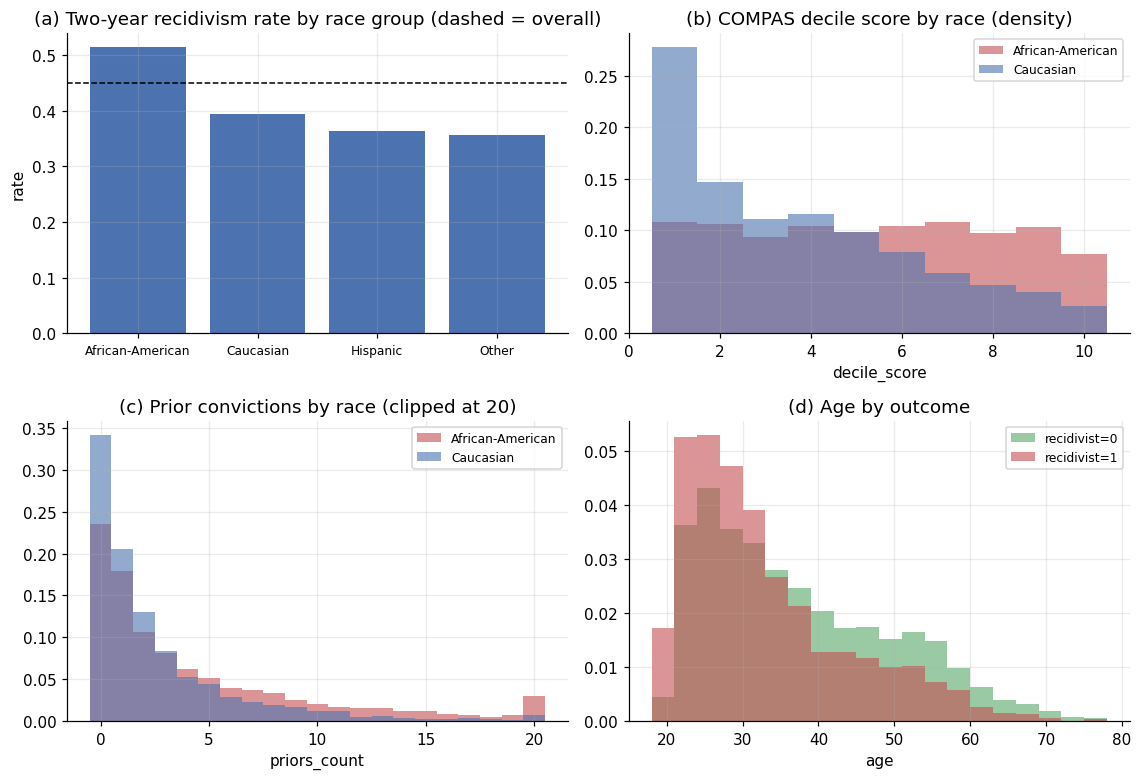

In [5]:
desc = df[CONT + ["decile_score"]].describe().T.round(2); save_table(desc, "descriptives"); display(desc)
by_race = df.groupby("race_group").agg(n=("id", "size"), recid_rate=("is_recidivist", "mean"),
                                       mean_decile=("decile_score", "mean"), mean_priors=("priors_count", "mean"),
                                       mean_age=("age", "mean")).round(3)
by_sex = df.groupby("sex").agg(n=("id", "size"), recid_rate=("is_recidivist", "mean"), mean_decile=("decile_score", "mean"), mean_priors=("priors_count", "mean"), mean_age=("age", "mean")).round(3)
save_table(by_race, "eda_by_race"); save_table(by_sex, "eda_by_sex"); display(by_race); display(by_sex)
raw_race = df.groupby("race").agg(n=("id", "size"), recid_rate=("is_recidivist", "mean")).round(3); display(raw_race)

R["eda"] = {"base_rate": float(df.is_recidivist.mean()),
            "by_race": by_race.reset_index().to_dict("records"), "by_sex": by_sex.reset_index().to_dict("records"),
            "corr_age_priors": float(df.age.corr(df.priors_count)),
            "corr_priors_recid": float(df.priors_count.corr(df.is_recidivist)),
            "corr_priors_AA": float(df.priors_count.corr(df.race_African_American)),
            "corr_decile_recid": float(df.decile_score.corr(df.is_recidivist))}

fig, ax = plt.subplots(2, 2, figsize=(10.5, 7.2))
order = ["African-American", "Caucasian", "Hispanic", "Other"]
ax[0,0].bar(order, [by_race.loc[o, "recid_rate"] for o in order], color="#4C72B0"); ax[0,0].axhline(df.is_recidivist.mean(), color="k", ls="--", lw=1)
ax[0,0].set_title("(a) Two-year recidivism rate by race group (dashed = overall)"); ax[0,0].set_ylabel("rate"); ax[0,0].tick_params(axis="x", labelsize=8)
for g, col in [("African-American", "#C44E52"), ("Caucasian", "#4C72B0")]:
    ax[0,1].hist(df.loc[df.race == g, "decile_score"], bins=np.arange(.5, 11.5), alpha=.6, label=g, color=col, density=True)
ax[0,1].set_title("(b) COMPAS decile score by race (density)"); ax[0,1].set_xlabel("decile_score"); ax[0,1].legend(fontsize=8)
for g, col in [("African-American", "#C44E52"), ("Caucasian", "#4C72B0")]:
    ax[1,0].hist(df.loc[df.race == g, "priors_count"].clip(upper=20), bins=np.arange(-.5, 21.5, 1), alpha=.6, label=g, color=col, density=True)
ax[1,0].set_title("(c) Prior convictions by race (clipped at 20)"); ax[1,0].set_xlabel("priors_count"); ax[1,0].legend(fontsize=8)
for v, col in [(0, "#55A868"), (1, "#C44E52")]:
    ax[1,1].hist(df.loc[df.is_recidivist == v, "age"], bins=range(18, 80, 3), alpha=.6, label=f"recidivist={v}", color=col, density=True)
ax[1,1].set_title("(d) Age by outcome"); ax[1,1].set_xlabel("age"); ax[1,1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig1_eda.png", dpi=200); plt.show()

## 4 · Train/test split (70/30, `random_state=450`) and leakage-safe scaling

In [6]:
train_df, test_df = train_test_split(df, test_size=0.30, random_state=SEED)
scaler = StandardScaler().fit(train_df[CONT])            # fitted on TRAIN ONLY

def design(d, drop=()):
    Z = pd.DataFrame(scaler.transform(d[CONT]), index=d.index, columns=CONT)
    X = pd.concat([Z, d[BIN].astype(float)], axis=1)
    X.insert(0, "const", 1.0)
    return X.drop(columns=list(drop))

Xtr, Xte, Xall = design(train_df), design(test_df), design(df)
ytr, yte, yall = train_df.is_recidivist, test_df.is_recidivist, df.is_recidivist
dtr, dte = train_df.decile_score, test_df.decile_score

R["split"] = {"seed": SEED, "n_train": int(len(train_df)), "n_test": int(len(test_df)),
              "test_frac": float(len(test_df) / len(df)),
              "base_rate_train": float(ytr.mean()), "base_rate_test": float(yte.mean()),
              "majority_baseline_acc_test": float(1 - yte.mean()),
              "scaler_mean": dict(zip(CONT, map(float, scaler.mean_))), "scaler_sd": dict(zip(CONT, map(float, scaler.scale_)))}
print(R["split"])

{'seed': 450, 'n_train': 5049, 'n_test': 2165, 'test_frac': 0.30011089548100917, 'base_rate_train': 0.44919786096256686, 'base_rate_test': 0.45404157043879906, 'majority_baseline_acc_test': 0.545958429561201, 'scaler_mean': {'age': 34.868290750643695, 'priors_count': 3.4367201426024954, 'juv_fel_count': 0.0629827688651218, 'juv_misd_count': 0.08199643493761141, 'juv_other_count': 0.10754604872251931}, 'scaler_sd': {'age': 11.951952179166522, 'priors_count': 4.866366966035414, 'juv_fel_count': 0.4560222844617424, 'juv_misd_count': 0.4174955453527021, 'juv_other_count': 0.5059758744941768}}


## 5 · Part 1 — Build the two models
* **Model A** – OLS linear regression predicting the continuous COMPAS `decile_score` (1–10).
* **Model B** – logistic regression (unpenalised maximum likelihood) predicting `is_recidivist`.

Both use the same 10 features and the same train/test split. `statsmodels` supplies coefficients, CIs and p-values; `scikit-learn` is used as an independent cross-check.

In [7]:
ols = sm.OLS(dtr, Xtr).fit()
logit = sm.Logit(ytr, Xtr).fit(disp=0)
print(ols.summary().tables[1]); print(logit.summary().tables[1])

pa = ols.predict(Xte)        # Model A test predictions (decile scale)
pb = logit.predict(Xte)      # Model B test probabilities

def coef_table(m):
    ci = m.conf_int(); ci.columns = ["ci_low", "ci_high"]
    return pd.concat([m.params.rename("coef"), m.bse.rename("se"), ci, m.pvalues.rename("p")], axis=1)
save_table(coef_table(ols), "modelA_ols_coefficients"); save_table(coef_table(logit), "modelB_logit_coefficients")

# independent cross-check with scikit-learn
sk_lin = LinearRegression().fit(Xtr.drop(columns="const"), dtr)
sk_log = LogisticRegression(C=np.inf, tol=1e-10, max_iter=100000).fit(Xtr.drop(columns="const"), ytr)
chk_A = float(np.abs(sk_lin.predict(Xte.drop(columns="const")) - pa).max())
chk_B = float(np.abs(sk_log.predict_proba(Xte.drop(columns="const"))[:, 1] - pb).max())
print("max |sklearn - statsmodels|  A:", chk_A, " B:", chk_B)

R["modelA"] = {"r2_train": float(ols.rsquared), "r2_test": float(r2_score(dte, pa)),
               "rmse_test": float(mean_squared_error(dte, pa) ** .5), "mae_test": float(mean_absolute_error(dte, pa)),
               "median_pred": float(np.median(pa)), "mean_pred": float(pa.mean()), "pred_min": float(pa.min()), "pred_max": float(pa.max()),
               "mean_actual_decile_test": float(dte.mean()), "sklearn_max_diff": chk_A,
               "coef": coef_table(ols).round(6).to_dict("index")}
yhat_B = (pb >= .5).astype(int)
R["modelB"] = {"accuracy": float(accuracy_score(yte, yhat_B)), "auc": float(roc_auc_score(yte, pb)),
               "precision": float(precision_score(yte, yhat_B)), "recall": float(recall_score(yte, yhat_B)),
               "f1": float(f1_score(yte, yhat_B)), "brier": float(brier_score_loss(yte, pb)), "logloss": float(log_loss(yte, pb)),
               "pseudo_r2_train": float(logit.prsquared), "flag_rate_at_0.5": float(yhat_B.mean()),
               "sklearn_max_diff": chk_B, "coef": coef_table(logit).round(6).to_dict("index")}
R["modelA"]["auc_vs_outcome"] = float(roc_auc_score(yte, pa))
pd.DataFrame({"Model A (OLS, decile_score)": {"R2 test": R["modelA"]["r2_test"], "RMSE": R["modelA"]["rmse_test"], "MAE": R["modelA"]["mae_test"]},
              "Model B (Logit)": {"Accuracy@0.5": R["modelB"]["accuracy"], "AUC": R["modelB"]["auc"], "Brier": R["modelB"]["brier"]}}).round(4)

                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     4.0364      0.089     45.345      0.000       3.862       4.211
age                      -1.1922      0.033    -36.576      0.000      -1.256      -1.128
priors_count              1.2330      0.034     36.775      0.000       1.167       1.299
juv_fel_count             0.1783      0.031      5.752      0.000       0.118       0.239
juv_misd_count            0.1330      0.033      4.080      0.000       0.069       0.197
juv_other_count           0.1403      0.032      4.384      0.000       0.078       0.203
male                     -0.0524      0.078     -0.671      0.502      -0.205       0.101
felony                    0.3869      0.065      5.995      0.000       0.260       0.513
race_African_American     0.5874      0.070      8.387      0.000       0.450       0.725
race_Hispa

,"Model A (OLS, decile_score)",Model B (Logit)
R2 test,0.4224,NaN
RMSE,2.1731,NaN
MAE,1.7542,NaN
Accuracy@0.5,NaN,0.6790
AUC,NaN,0.7341
Brier,NaN,0.2083


## 6 · Part 1 — Threshold comparison and mismatch analysis
* Model A → "high risk" if prediction ≥ **median of Model A's test predictions**.
* Model B → "high risk" if predicted probability ≥ **0.5**.

*Agreement between the two flags is **not** accuracy*: the second table scores each flag against the **actual** outcome.

In [8]:
med = float(np.median(pa))
hiA, hiB = (pa >= med), (pb >= .5)
n = len(pa)
cm = pd.DataFrame([[int((~hiA & ~hiB).sum()), int((~hiA & hiB).sum())],
                   [int((hiA & ~hiB).sum()),  int((hiA & hiB).sum())]],
                  index=["Model A: low risk", "Model A: high risk"], columns=["Model B: low risk", "Model B: high risk"])
display(cm); save_table(cm, "part1_confusion_matrix_A_vs_B")
mis = int((hiA != hiB).sum())
AhBl, AlBh = int((hiA & ~hiB).sum()), int((~hiA & hiB).sum())

def score_flag(flag):
    tn, fp = int(((flag == 0) & (yte == 0)).sum()), int(((flag == 1) & (yte == 0)).sum())
    fn, tp = int(((flag == 0) & (yte == 1)).sum()), int(((flag == 1) & (yte == 1)).sum())
    return {"flag_rate": float(flag.mean()), "accuracy": (tp + tn) / n, "precision": tp / (tp + fp), "recall": tp / (tp + fn),
            "FPR": fp / (fp + tn), "TP": tp, "FP": fp, "TN": tn, "FN": fn}
vs_actual = pd.DataFrame({"Model A flag (>= median)": score_flag(hiA.astype(int)), "Model B flag (p >= 0.5)": score_flag(hiB.astype(int))}).T
display(vs_actual.round(4)); save_table(vs_actual, "part1_flags_vs_actual_outcome")

# why do they differ?  (i) rank agreement, (ii) threshold semantics, (iii) quantile-matched B threshold
t_match = float(np.quantile(pb, 1 - hiA.mean()))
hiB_match = (pb >= t_match)
mis_match = int((hiA != hiB_match).sum())
mism = hiA != hiB
R["part1"] = {"n_test": n, "median_pred_A": med, "flag_rate_A": float(hiA.mean()), "flag_rate_B": float(hiB.mean()),
              "n_flag_A": int(hiA.sum()), "n_flag_B": int(hiB.sum()),
              "cm": {"AL_BL": int(cm.iloc[0,0]), "AL_BH": int(cm.iloc[0,1]), "AH_BL": int(cm.iloc[1,0]), "AH_BH": int(cm.iloc[1,1])},
              "mismatch_n": mis, "mismatch_pct": 100 * mis / n, "agree_n": n - mis, "agree_pct": 100 * (n - mis) / n,
              "AhBl": AhBl, "AlBh": AlBh,
              "spearman_A_B": float(stats.spearmanr(pa, pb)[0]), "pearson_A_B": float(np.corrcoef(pa, pb)[0, 1]),
              "mismatch_mean_pB": float(pb[mism].mean()), "mismatch_min_pB": float(pb[mism].min()), "mismatch_max_pB": float(pb[mism].max()),
              "mismatch_AhBl_mean_pB": float(pb[hiA & ~hiB].mean()), "mismatch_AhBl_mean_pA": float(pa[hiA & ~hiB].mean()),
              "mismatch_AlBh_mean_pB": float(pb[~hiA & hiB].mean()) if AlBh else None,
              "pB_matched_threshold": t_match, "mismatch_matched_n": mis_match, "mismatch_matched_pct": 100 * mis_match / n,
              "vs_actual": vs_actual.round(6).to_dict("index"),
              "agree_both_correct": int(((hiA == yte) & (hiB == yte)).sum()),
              "agree_but_both_wrong": int(((hiA == hiB) & (hiA != yte)).sum()),
              "mismatch_A_right": int((mism & (hiA == yte)).sum()), "mismatch_B_right": int((mism & (hiB == yte)).sum()),
              "mean_decile_all": float(df.decile_score.mean()), "decile_median_all": float(df.decile_score.median())}
for k in ["mismatch_n","mismatch_pct","AhBl","AlBh","median_pred_A","flag_rate_A","flag_rate_B","pB_matched_threshold","mismatch_matched_pct","spearman_A_B","mismatch_A_right","mismatch_B_right"]:
    print(k, R["part1"][k])

,Model B: low risk,Model B: high risk
Model A: low risk,1068,13
Model A: high risk,283,801


,flag_rate,accuracy,precision,recall,FPR,TP,FP,TN,FN
Model A flag (>= median),0.5007,0.6596,0.6135,0.6765,0.3545,665.0,419.0,763.0,318.0
Model B flag (p >= 0.5),0.3760,0.6790,0.6769,0.5605,0.2225,551.0,263.0,919.0,432.0


mismatch_n 296
mismatch_pct 13.672055427251733
AhBl 283
AlBh 13
median_pred_A 4.592278607514044
flag_rate_A 0.5006928406466513
flag_rate_B 0.3759815242494226
pB_matched_threshold 0.4486927152624019
mismatch_matched_pct 10.161662817551964
spearman_A_B 0.96011949007863
mismatch_A_right 127
mismatch_B_right 169


## 7 · Part 2.1 — Simpson's-paradox hunt
**Design.** Inference models (not prediction) are fitted on the *whole* dataset (all 7,214 rows) for the "full" model and on each subgroup, using the **same feature set** in all three so coefficients are comparable (the split variable is omitted from the design, because it is constant within a subgroup). Continuous features use the training-set z-scores, so coefficients are log-odds **per 1 SD**.

**Difference test.** For predictor *j* the difference between subgroup fits is tested with
`z = (β_A − β_B) / sqrt(se_A² + se_B²)` (independent samples). Overlapping CIs alone are *not* used to infer "no difference".

**Honest scan.** Because I am *looking* for a reversal, I first scan 3 demographic splits (race, sex, age ≤30 vs >30) × all predictors and apply a **Bonferroni** correction over all tests, so a lucky p-value is not mistaken for a finding. The split that is then reported in detail (**sex**) is the one containing a difference that survives this correction; it is therefore a post-hoc choice, declared as such. The race split (the focus of Part 2.4) is reported as a secondary table.

In [9]:
def fit_logit(X, y): return sm.Logit(y, X).fit(disp=0, maxiter=300)
RACE_DUMMIES = ["race_African_American", "race_Hispanic", "race_Other"]
AA, CA = (df.race == "African-American"), (df.race == "Caucasian")
splits = {"race (African-American vs Caucasian)": (AA, CA, RACE_DUMMIES),
          "sex (Male vs Female)": (df.male == 1, df.male == 0, ["male"]),
          "age (<=30 vs >30)": (df.age <= 30, df.age > 30, [])}

scan_rows = []
for sname, (ga, gb, drop) in splits.items():
    cols = [c for c in Xall.columns if c not in drop]
    ma, mb = fit_logit(Xall.loc[ga, cols], yall[ga]), fit_logit(Xall.loc[gb, cols], yall[gb])
    for c in cols[1:]:
        z = (ma.params[c] - mb.params[c]) / np.sqrt(ma.bse[c] ** 2 + mb.bse[c] ** 2)
        scan_rows.append({"split": sname, "predictor": c, "beta_A": ma.params[c], "beta_B": mb.params[c],
                          "ciA_low": ma.conf_int().loc[c, 0], "ciA_high": ma.conf_int().loc[c, 1],
                          "ciB_low": mb.conf_int().loc[c, 0], "ciB_high": mb.conf_int().loc[c, 1],
                          "sign_flip": bool(np.sign(ma.params[c]) != np.sign(mb.params[c])),
                          "both_CIs_exclude_0": bool((ma.pvalues[c] < .05) and (mb.pvalues[c] < .05)),
                          "diff_z": z, "diff_p": 2 * stats.norm.sf(abs(z))})
scan = pd.DataFrame(scan_rows)
k_tests = len(scan); scan["p_bonferroni"] = (scan.diff_p * k_tests).clip(upper=1)
save_table(scan.round(5), "part21_scan_all_splits", index=False)
print("tests:", k_tests, " Bonferroni alpha:", .05 / k_tests)
display(scan[scan.sign_flip].round(4))
display(scan[scan.p_bonferroni < .05].round(4)[["split","predictor","beta_A","beta_B","diff_p","p_bonferroni"]])
R["p21_scan"] = {"n_tests": k_tests, "bonferroni_alpha": .05 / k_tests,
                 "n_sign_flips": int(scan.sign_flip.sum()), "n_sig_diff_nominal": int((scan.diff_p < .05).sum()),
                 "n_sig_diff_bonferroni": int((scan.p_bonferroni < .05).sum()),
                 "sign_flips": scan[scan.sign_flip].round(5).to_dict("records"),
                 "sign_flips_with_both_sig": int((scan.sign_flip & scan.both_CIs_exclude_0).sum())}

tests: 26  Bonferroni alpha: 0.0019230769230769232


,split,predictor,beta_A,beta_B,ciA_low,ciA_high,ciB_low,ciB_high,sign_flip,both_CIs_exclude_0,diff_z,diff_p,p_bonferroni
3,race (African-American vs Caucasian),juv_misd_count,-0.0310,0.0825,-0.0968,0.0348,-0.0653,0.2304,True,False,-1.3748,0.1692,1.0000
10,sex (Male vs Female),juv_misd_count,0.0122,-0.0263,-0.0500,0.0744,-0.2114,0.1588,True,False,0.3862,0.6993,1.0000
13,sex (Male vs Female),race_African_American,0.1108,-0.2309,-0.0168,0.2384,-0.4907,0.0289,True,False,2.3138,0.0207,0.5377
23,age (<=30 vs >30),race_African_American,0.2094,-0.1167,0.0408,0.3781,-0.2755,0.0422,True,False,2.7587,0.0058,0.1509
25,age (<=30 vs >30),race_Other,0.0003,-0.3491,-0.3359,0.3366,-0.6630,-0.0353,True,False,1.4890,0.1365,1.0000


,split,predictor,beta_A,beta_B,diff_p,p_bonferroni
8,sex (Male vs Female),priors_count,0.6660,1.0240,0.0016,0.0426
16,age (<=30 vs >30),age,-1.5605,-0.3824,0.0000,0.0000
17,age (<=30 vs >30),priors_count,1.2490,0.6409,0.0000,0.0000


,full_coef,full_lo,full_hi,full_p,A_coef,A_lo,A_hi,A_p,B_coef,B_lo,B_hi,B_p,diff_AminusB,diff_z,diff_p,diff_p_bonferroni,sign_flip,OR_A,OR_B,OR_full
age,-0.5268,-0.5862,-0.4673,0.0000,-0.5416,-0.6072,-0.4760,0.0000,-0.4685,-0.6104,-0.3266,0.0000,-0.0731,-0.9168,0.3593,1.0000,False,0.5818,0.6260,0.5905
priors_count,0.7206,0.6528,0.7883,0.0000,0.6660,0.5944,0.7376,0.0000,1.0240,0.8130,1.2351,0.0000,-0.3580,-3.1488,0.0016,0.0426,False,1.9465,2.7844,2.0556
juv_fel_count,0.0805,0.0063,0.1548,0.0336,0.0782,0.0028,0.1535,0.0420,0.0458,-0.3508,0.4424,0.8210,0.0324,0.1574,0.8750,1.0000,False,1.0813,1.0468,1.0838
juv_misd_count,0.0095,-0.0495,0.0686,0.7515,0.0122,-0.0500,0.0744,0.7012,-0.0263,-0.2114,0.1588,0.7807,0.0385,0.3862,0.6993,1.0000,True,1.0123,0.9740,1.0096
juv_other_count,0.1000,0.0376,0.1623,0.0017,0.0928,0.0269,0.1587,0.0058,0.0647,-0.1213,0.2507,0.4956,0.0281,0.2792,0.7801,1.0000,False,1.0972,1.0668,1.1051
felony,0.1801,0.0737,0.2865,0.0009,0.1229,0.0042,0.2416,0.0425,0.3313,0.0827,0.5799,0.0090,-0.2084,-1.4826,0.1382,1.0000,False,1.1308,1.3928,1.1973
race_African_American,0.0491,-0.0649,0.1631,0.3982,0.1108,-0.0168,0.2384,0.0888,-0.2309,-0.4907,0.0289,0.0815,0.3417,2.3138,0.0207,0.5377,True,1.1172,0.7938,1.0504
race_Hispanic,-0.1761,-0.3680,0.0159,0.0723,-0.1955,-0.4057,0.0146,0.0682,-0.1422,-0.6221,0.3378,0.5615,-0.0534,-0.1996,0.8418,1.0000,False,0.8224,0.8675,0.8386
race_Other,-0.1880,-0.4140,0.0379,0.1029,-0.1633,-0.4104,0.0837,0.1951,-0.3857,-0.9626,0.1911,0.1900,0.2224,0.6947,0.4873,1.0000,False,0.8493,0.6800,0.8286


,n,mean_pred,observed
Male|all,1733.0,0.479,0.475
Male|priors>=5,509.0,0.672,0.697
Male|priors<=1,773.0,0.367,0.318
Female|all,432.0,0.358,0.368
Female|priors>=5,66.0,0.582,0.667
Female|priors<=1,249.0,0.288,0.245


,n_test,auc_pooled,auc_group_specific,logloss_pooled,logloss_group_specific
Male,1733.0,0.7332,0.7320,0.6099,0.6106
Female,432.0,0.7236,0.7183,0.5892,0.5912


{'male_beta': 0.6662160920408505, 'female_beta': 0.811343698741008, 'diff_z': -1.7831786136551384, 'diff_p': 0.07455723264739046}


,mean,median,std
sex,,,
Female,2.280,1.0,3.639
Male,3.758,2.0,5.095


,full_coef,full_lo,full_hi,full_p,A_coef,A_lo,A_hi,A_p,B_coef,B_lo,B_hi,B_p,diff_AminusB,diff_z,diff_p,diff_p_bonferroni,sign_flip,OR_A,OR_B,OR_full
age,-0.5339,-0.5924,-0.4755,0.0000,-0.6196,-0.7112,-0.5279,0.0000,-0.4352,-0.5259,-0.3445,0.0000,-0.1844,-2.8018,0.0051,0.1321,False,0.5382,0.6471,0.5863
priors_count,0.7224,0.6556,0.7892,0.0000,0.6636,0.5786,0.7487,0.0000,0.8560,0.7166,0.9955,0.0000,-0.1924,-2.3087,0.0210,0.5450,False,1.9418,2.3538,2.0594
juv_fel_count,0.0768,0.0028,0.1508,0.0419,0.0613,-0.0199,0.1425,0.1392,0.0473,-0.1340,0.2286,0.6090,0.0139,0.1376,0.8906,1.0000,False,1.0632,1.0485,1.0799
juv_misd_count,0.0093,-0.0499,0.0686,0.7577,-0.0310,-0.0968,0.0348,0.3559,0.0825,-0.0653,0.2304,0.2740,-0.1135,-1.3748,0.1692,1.0000,True,0.9695,1.0860,1.0094
juv_other_count,0.0953,0.0330,0.1575,0.0027,0.1770,0.0836,0.2703,0.0002,0.0092,-0.0867,0.1051,0.8509,0.1678,2.4565,0.0140,0.3647,False,1.1936,1.0092,1.1000
male,0.2872,0.1584,0.4161,0.0000,0.4558,0.2715,0.6402,0.0000,0.1151,-0.0926,0.3228,0.2775,0.3407,2.4045,0.0162,0.4211,False,1.5775,1.1220,1.3327
felony,0.1772,0.0708,0.2836,0.0011,0.1342,-0.0167,0.2851,0.0814,0.1602,-0.0204,0.3408,0.0821,-0.0260,-0.2165,0.8286,1.0000,False,1.1436,1.1737,1.1939


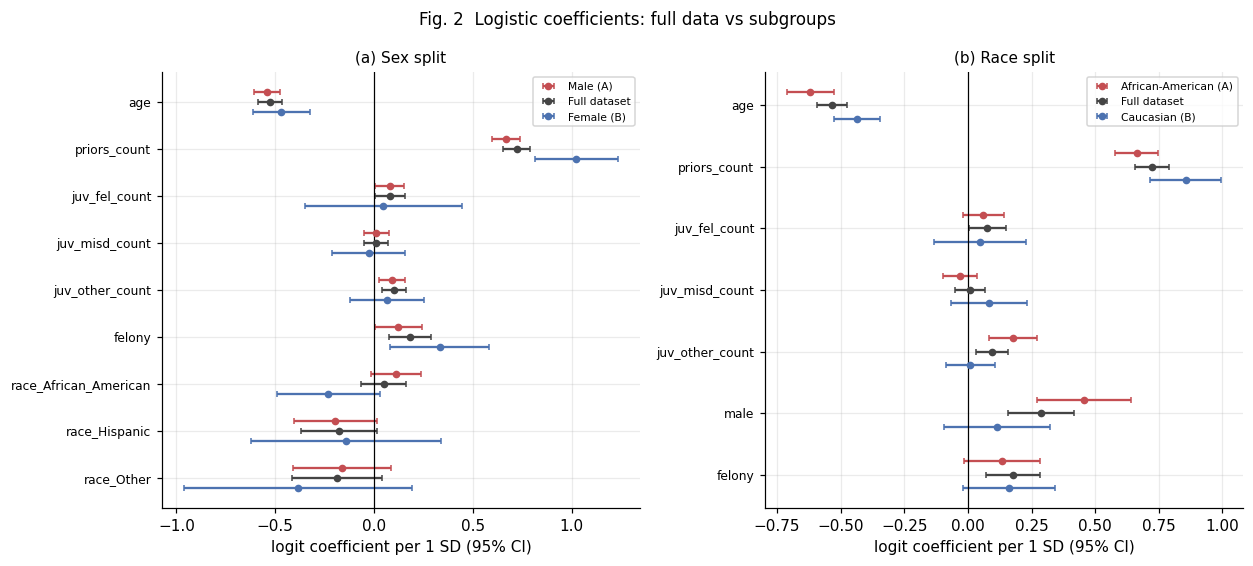

In [10]:
def split_analysis(ga, gb, drop):
    cols = [c for c in Xall.columns if c not in drop]
    models = {"full": fit_logit(Xall[cols], yall), "A": fit_logit(Xall.loc[ga, cols], yall[ga]), "B": fit_logit(Xall.loc[gb, cols], yall[gb])}
    T = {k: coef_table(m) for k, m in models.items()}
    tab = pd.DataFrame(index=cols[1:])
    for k in T:
        tab[f"{k}_coef"], tab[f"{k}_lo"], tab[f"{k}_hi"], tab[f"{k}_p"] = T[k].coef, T[k].ci_low, T[k].ci_high, T[k].p
    tab["diff_AminusB"] = tab.A_coef - tab.B_coef
    tab["diff_z"] = tab.diff_AminusB / np.sqrt(T["A"].se ** 2 + T["B"].se ** 2)
    tab["diff_p"] = 2 * stats.norm.sf(tab.diff_z.abs())
    tab["diff_p_bonferroni"] = (tab.diff_p * k_tests).clip(upper=1)
    tab["sign_flip"] = np.sign(tab.A_coef) != np.sign(tab.B_coef)
    for k in ["A", "B", "full"]: tab[f"OR_{k}"] = np.exp(tab[f"{k}_coef"])
    return cols, tab

def pooled_vs_group(group_col, label_a, label_b, cols):
    # test-set calibration of the pooled Model B, and group-specific models trained on TRAIN rows only
    cal = {}
    for lab in [label_a, label_b]:
        g = test_df[group_col] == lab
        for sub_lab, msk in [("all", g), ("priors>=5", g & (test_df.priors_count >= 5)), ("priors<=1", g & (test_df.priors_count <= 1))]:
            cal[f"{lab}|{sub_lab}"] = {"n": int(msk.sum()), "mean_pred": float(pb[msk].mean()), "observed": float(yte[msk].mean())}
    perf = {}
    for lab in [label_a, label_b]:
        tr_m, te_m = train_df[group_col] == lab, test_df[group_col] == lab
        m = fit_logit(Xtr.loc[tr_m, cols], ytr[tr_m]); p_sub = m.predict(Xte.loc[te_m, cols])
        perf[lab] = {"n_test": int(te_m.sum()), "auc_pooled": float(roc_auc_score(yte[te_m], pb[te_m])), "auc_group_specific": float(roc_auc_score(yte[te_m], p_sub)),
                     "logloss_pooled": float(log_loss(yte[te_m], pb[te_m])), "logloss_group_specific": float(log_loss(yte[te_m], p_sub))}
    return cal, perf

# =============== PRIMARY: split by SEX  (A = Male, B = Female) ===============
M_, F_ = (df.male == 1), (df.male == 0)
cols_sex, tab_sex = split_analysis(M_, F_, ["male"])
save_table(tab_sex.round(6), "part21_sex_split_coefficients"); display(tab_sex.round(4))
cal_sex, perf_sex = pooled_vs_group("sex", "Male", "Female", cols_sex)
display(pd.DataFrame(cal_sex).T.round(3)); display(pd.DataFrame(perf_sex).T.round(4))

# functional-form diagnostic: is the priors_count heterogeneity partly a linear-vs-log artefact?
tr_lp = np.log1p(train_df.priors_count)
Xlog = Xall.copy(); Xlog["priors_count"] = (np.log1p(df.priors_count) - tr_lp.mean()) / tr_lp.std()
mM_l, mF_l = fit_logit(Xlog.loc[M_, cols_sex], yall[M_]), fit_logit(Xlog.loc[F_, cols_sex], yall[F_])
z_l = (mM_l.params["priors_count"] - mF_l.params["priors_count"]) / np.sqrt(mM_l.bse["priors_count"] ** 2 + mF_l.bse["priors_count"] ** 2)
log_check = {"male_beta": float(mM_l.params["priors_count"]), "female_beta": float(mF_l.params["priors_count"]), "diff_z": float(z_l), "diff_p": float(2 * stats.norm.sf(abs(z_l)))}
print(log_check)
priors_by_sex = df.groupby("sex").priors_count.agg(["mean", "median", "std"]).round(3); display(priors_by_sex)

R["p21"] = {"primary": {"split": "sex", "label_A": "Male", "label_B": "Female", "n_full": int(len(df)), "n_A": int(M_.sum()), "n_B": int(F_.sum()),
                        "base_rate_A": float(yall[M_].mean()), "base_rate_B": float(yall[F_].mean()),
                        "table": tab_sex.round(6).reset_index().rename(columns={"index": "predictor"}).to_dict("records"),
                        "pooled_calibration": cal_sex, "group_vs_pooled_test": perf_sex, "log_check": log_check,
                        "priors_by_sex": priors_by_sex.to_dict("index")}}

# =============== SECONDARY: split by RACE  (A = African-American, B = Caucasian) ===============
cols_race, tab_race = split_analysis(AA, CA, RACE_DUMMIES)
save_table(tab_race.round(6), "part21_race_split_coefficients"); display(tab_race.round(4))
cal_race, perf_race = pooled_vs_group("race", "African-American", "Caucasian", cols_race)
R["p21"]["race"] = {"split": "race", "label_A": "African-American", "label_B": "Caucasian", "n_full": int(len(df)), "n_A": int(AA.sum()), "n_B": int(CA.sum()),
                    "base_rate_A": float(yall[AA].mean()), "base_rate_B": float(yall[CA].mean()),
                    "table": tab_race.round(6).reset_index().rename(columns={"index": "predictor"}).to_dict("records"),
                    "pooled_calibration": cal_race, "group_vs_pooled_test": perf_race}
# sex-split heterogeneity of the race coefficient (nominal sign flip) – exploratory only
row_sx = tab_sex.loc["race_African_American"]
R["p21"]["primary"]["race_coef_by_sex"] = {"male": [row_sx.A_coef, row_sx.A_lo, row_sx.A_hi, row_sx.A_p], "female": [row_sx.B_coef, row_sx.B_lo, row_sx.B_hi, row_sx.B_p],
                                           "diff_p": float(row_sx.diff_p), "diff_p_bonferroni": float(row_sx.diff_p_bonferroni)}

# forest plots
fig, axs = plt.subplots(1, 2, figsize=(11.5, 5.2))
for ax, tab, lab, title in [(axs[0], tab_sex, ("Male (A)", "Female (B)"), "(a) Sex split"), (axs[1], tab_race, ("African-American (A)", "Caucasian (B)"), "(b) Race split")]:
    names = list(tab.index); ypos = np.arange(len(names))[::-1]
    for off, key, col, l in [(.22, "A", "#C44E52", lab[0]), (0, "full", "#444444", "Full dataset"), (-.22, "B", "#4C72B0", lab[1])]:
        ax.errorbar(tab[f"{key}_coef"], ypos + off, xerr=[tab[f"{key}_coef"] - tab[f"{key}_lo"], tab[f"{key}_hi"] - tab[f"{key}_coef"]], fmt="o", ms=4, color=col, capsize=2, label=l)
    ax.axvline(0, color="k", lw=.8); ax.set_yticks(ypos); ax.set_yticklabels(names, fontsize=8); ax.set_xlabel("logit coefficient per 1 SD (95% CI)"); ax.set_title(title, fontsize=10); ax.legend(fontsize=7)
fig.suptitle("Fig. 2  Logistic coefficients: full data vs subgroups", fontsize=11)
plt.tight_layout(); plt.savefig(FIG / "fig2_subgroup_forest.png", dpi=200); plt.show()

## 8 · Part 2.2 — Omitted-variable bias
**Dropped variable: `priors_count`.** Rationale: it is (i) the strongest predictor of recidivism, (ii) correlated with the
other predictors – age, juvenile counts and race (see correlations below) – so it can absorb their effects when removed,
and (iii) is itself shaped by policing intensity/exposure. Full model = Model B (training set); reduced model = same
without `priors_count`.

**Percentage change formula:** `%Δ = (β_reduced − β_full) / |β_full| × 100`. Because this explodes when β_full ≈ 0, the table also reports the absolute change and the change in units of the full model's standard error.

,beta_full,p_full,beta_reduced,p_reduced,abs_change,pct_change,change_in_SE_units,sign_flip,sig_full,sig_reduced
age,-0.5257,0.0000,-0.3122,0.0000,0.2135,40.6183,5.9169,False,True,True
juv_fel_count,0.0538,0.2382,0.1837,0.0001,0.1299,241.2629,2.8456,False,False,True
juv_misd_count,-0.0179,0.6116,0.1088,0.0018,0.1267,708.4343,3.5976,True,False,True
juv_other_count,0.0492,0.1702,0.1039,0.0050,0.0548,111.3948,1.5278,False,False,True
male,0.3194,0.0001,0.4338,0.0000,0.1144,35.8185,1.4450,False,True,True
felony,0.2077,0.0013,0.3544,0.0000,0.1467,70.6072,2.2662,False,True,True
race_African_American,0.0983,0.1578,0.3024,0.0000,0.2041,207.6847,2.9334,False,False,True
race_Hispanic,-0.0884,0.4414,-0.1236,0.2653,-0.0352,-39.8471,-0.3068,False,False,False
race_Other,-0.1800,0.1899,-0.2386,0.0748,-0.0586,-32.5864,-0.4272,False,False,False


juv_misd_count age age


,corr with priors_count
age,0.169
juv_fel_count,0.176
juv_misd_count,0.221
juv_other_count,0.104
male,0.119
felony,0.132
race_African_American,0.191
race_Hispanic,-0.079
race_Other,-0.075


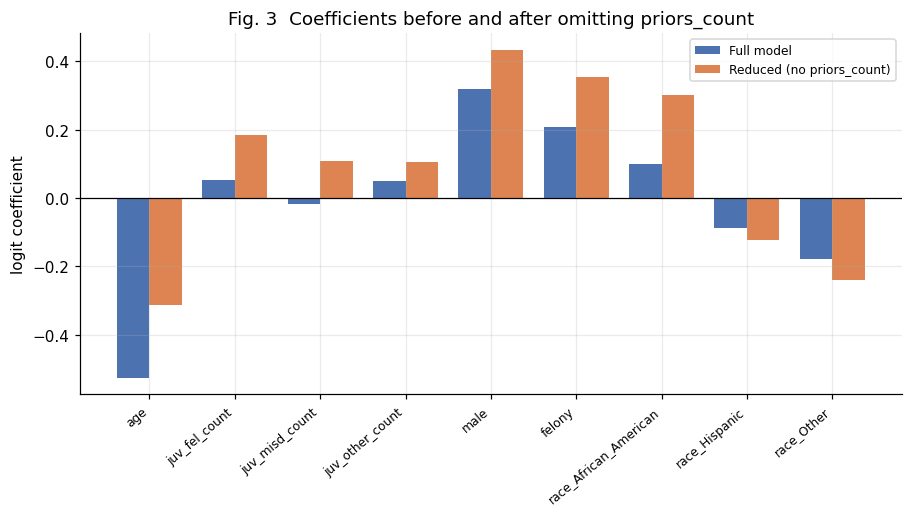

In [11]:
Xtr_red = Xtr.drop(columns=["priors_count"]); Xte_red = Xte.drop(columns=["priors_count"])
m_red = fit_logit(Xtr_red, ytr)
cf, cr = coef_table(logit), coef_table(m_red)
preds = [c for c in Xtr_red.columns if c != "const"]
ovb = pd.DataFrame({"beta_full": cf.loc[preds, "coef"], "p_full": cf.loc[preds, "p"], "beta_reduced": cr.loc[preds, "coef"], "p_reduced": cr.loc[preds, "p"]})
ovb["abs_change"] = ovb.beta_reduced - ovb.beta_full
ovb["pct_change"] = ovb.abs_change / ovb.beta_full.abs() * 100
ovb["change_in_SE_units"] = ovb.abs_change / cf.loc[preds, "se"]
ovb["sign_flip"] = np.sign(ovb.beta_full) != np.sign(ovb.beta_reduced)
ovb["sig_full"] = ovb.p_full < .05; ovb["sig_reduced"] = ovb.p_reduced < .05
save_table(ovb.round(6), "part22_omitted_variable"); display(ovb.round(4))
corr_p = Xtr.drop(columns="const").corrwith(Xtr["priors_count"]).drop("priors_count")
perf_full = {"auc": roc_auc_score(yte, pb), "logloss": log_loss(yte, pb), "acc": accuracy_score(yte, pb >= .5)}
pr_red = m_red.predict(Xte_red); perf_red = {"auc": roc_auc_score(yte, pr_red), "logloss": log_loss(yte, pr_red), "acc": accuracy_score(yte, pr_red >= .5)}
R["p22"] = {"dropped": "priors_count", "table": ovb.round(6).reset_index().rename(columns={"index": "predictor"}).to_dict("records"),
            "largest_pct": ovb["pct_change"].abs().idxmax(), "largest_abs": ovb.abs_change.abs().idxmax(), "largest_se": ovb.change_in_SE_units.abs().idxmax(),
            "corr_with_priors": corr_p.round(4).to_dict(), "corr_priors_outcome_train": float(Xtr.priors_count.corr(ytr)),
            "priors_coef_full": float(cf.loc["priors_count", "coef"]), "perf_full": {k: float(v) for k, v in perf_full.items()},
            "perf_reduced": {k: float(v) for k, v in perf_red.items()},
            "n_sign_flips": int(ovb.sign_flip.sum()), "n_sig_gain": int((~ovb.sig_full & ovb.sig_reduced).sum()),
            "n_sig_lost": int((ovb.sig_full & ~ovb.sig_reduced).sum())}
print(R["p22"]["largest_pct"], R["p22"]["largest_abs"], R["p22"]["largest_se"]); display(corr_p.round(3).to_frame("corr with priors_count"))

fig, ax = plt.subplots(figsize=(8.4, 4.8)); w = .38; xs = np.arange(len(preds))
ax.bar(xs - w/2, ovb.beta_full, w, label="Full model", color="#4C72B0"); ax.bar(xs + w/2, ovb.beta_reduced, w, label="Reduced (no priors_count)", color="#DD8452")
ax.axhline(0, color="k", lw=.8); ax.set_xticks(xs); ax.set_xticklabels(preds, rotation=40, ha="right", fontsize=8); ax.set_ylabel("logit coefficient")
ax.set_title("Fig. 3  Coefficients before and after omitting priors_count"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig3_omitted_variable.png", dpi=200); plt.show()

## 9 · Part 2.3 — Adversarial subset construction
False positives: P ≥ 0.75 and actual = 0. False negatives: P ≤ 0.25 and actual = 1. If more than 50 qualify, 50 are drawn at random with `random_state=450`.
Besides profiling the rows, I check **whether the "confident errors" exceed what the model's own probabilities already imply** (a calibrated model must make some of them) and whether adding non-linear/interaction terms would remove them.

{'n_fp': 35, 'n_fn': 55, 'n_qualifying': 90, 'pct_of_test': 4.157043879907621, 'n_subset': 50, 'subset_n_fp': 21, 'subset_n_fn': 29}
expected under calibration  FP: 28.0  FN: 60.4


,Full test set,Adversarial subset (50),of which false positives,of which false negatives,All qualifying errors (90)
n,2165.00,50.00,21.00,29.00,90.00
age_mean,34.70,45.96,38.52,51.34,46.66
age_median,31.00,47.50,37.00,50.00,48.50
pct_age_lt25,20.05,0.00,0.00,0.00,1.11
pct_age_ge45,21.15,56.00,19.05,82.76,60.00
pct_male,80.05,72.00,95.24,55.17,77.78
pct_African_American,51.55,44.00,80.95,17.24,42.22
pct_Caucasian,34.50,48.00,14.29,72.41,47.78
pct_Hispanic,8.08,6.00,4.76,6.90,6.67
pct_Other,5.87,2.00,0.00,3.45,3.33


,trait,group,n,pct_in_group,pct_in_rest_of_test,fisher_p
0,age < 25,all 50,50,0.0000,20.5201,0.0000
1,age < 25,FP only,21,0.0000,20.5201,0.0127
2,age < 25,FN only,29,0.0000,20.5201,0.0020
3,age >= 45,all 50,50,56.0000,20.3310,0.0000
4,age >= 45,FP only,21,19.0476,20.3310,1.0000
5,age >= 45,FN only,29,82.7586,20.3310,0.0000
6,male,all 50,50,72.0000,80.2364,0.1533
7,male,FP only,21,95.2381,80.2364,0.0996
8,male,FN only,29,55.1724,80.2364,0.0035
9,African-American,all 50,50,44.0000,51.7258,0.3173


{'lr_stat': 81.848907042483, 'df': 6, 'lr_p': 1.4821341102627965e-15, 'auc_base': 0.734109730047009, 'auc_ext': 0.7389948068088124, 'logloss_base': 0.6057839881594915, 'logloss_ext': 0.5981096720915225, 'n_conf_errors_ext': 114, 'n_conf_errors_base': 90, 'coef': {'priors_sq': {'coef': -0.0859, 'se': 0.02078, 'ci_low': -0.12663, 'ci_high': -0.04517, 'p': 4e-05}, 'age_sq': {'coef': 0.19551, 'se': 0.02882, 'ci_low': 0.13901, 'ci_high': 0.252, 'p': 0.0}, 'age_x_priors': {'coef': -0.08765, 'se': 0.03947, 'ci_low': -0.165, 'ci_high': -0.0103, 'p': 0.02636}, 'felony_x_priors': {'coef': -0.0214, 'se': 0.07735, 'ci_low': -0.173, 'ci_high': 0.13019, 'p': 0.78198}, 'male_x_priors': {'coef': -0.26043, 'se': 0.12235, 'ci_low': -0.50024, 'ci_high': -0.02063, 'p': 0.03329}, 'AA_x_priors': {'coef': -0.15372, 'se': 0.07787, 'ci_low': -0.30634, 'ci_high': -0.00111, 'p': 0.04836}}}


,test,FP rows,FN rows
age,-0.01,0.31,1.38
priors_count,0.02,3.08,-0.54
juv_fel_count,0.03,0.38,-0.14
juv_misd_count,0.07,0.03,-0.20
juv_other_count,0.01,-0.21,-0.21


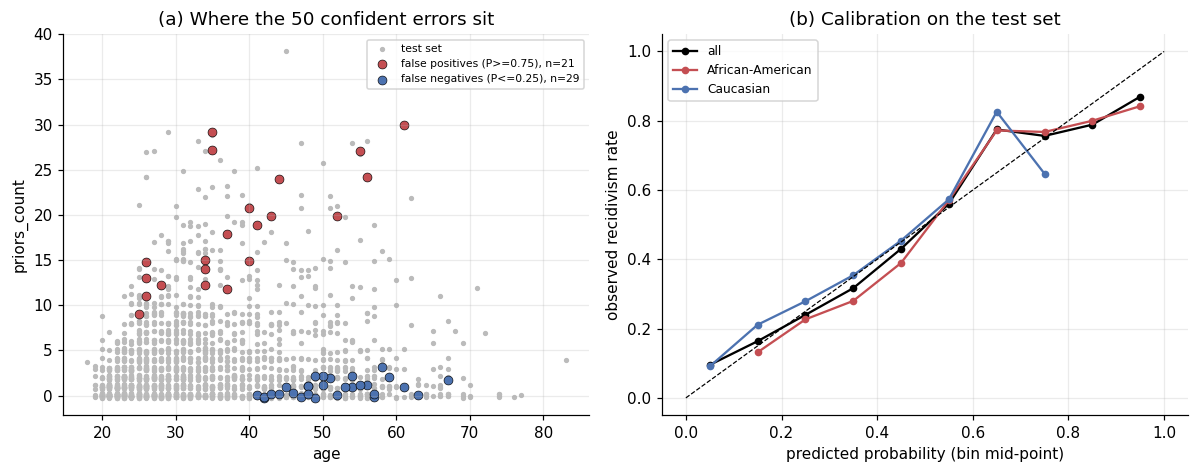

In [12]:
res = test_df.assign(p=pb, y=yte)
fp_mask = (res.p >= .75) & (res.y == 0); fn_mask = (res.p <= .25) & (res.y == 1)
qual = res[fp_mask | fn_mask].copy(); qual["error_type"] = np.where(qual.y == 0, "FP", "FN")
n_q = len(qual); n_sub = min(50, n_q)
sub = qual.sample(n=n_sub, random_state=SEED) if n_q > 50 else qual
conf_hi, conf_lo = res[res.p >= .75], res[res.p <= .25]
exp_fp, exp_fn = float((1 - conf_hi.p).sum()), float(conf_lo.p.sum())
R["p23"] = {"n_fp": int(fp_mask.sum()), "n_fn": int(fn_mask.sum()), "n_qualifying": int(n_q), "pct_of_test": 100 * n_q / len(res), "n_subset": int(n_sub),
            "subset_n_fp": int((sub.error_type == "FP").sum()), "subset_n_fn": int((sub.error_type == "FN").sum()), "sample_seed": SEED,
            "n_conf_pos": int(len(conf_hi)), "n_conf_neg": int(len(conf_lo)),
            "obs_pos_rate_when_p_ge_75": float(conf_hi.y.mean()), "mean_p_when_p_ge_75": float(conf_hi.p.mean()),
            "obs_pos_rate_when_p_le_25": float(conf_lo.y.mean()), "mean_p_when_p_le_25": float(conf_lo.p.mean()),
            "expected_fp_if_calibrated": exp_fp, "expected_fn_if_calibrated": exp_fn}
print({k: R["p23"][k] for k in ["n_fp", "n_fn", "n_qualifying", "pct_of_test", "n_subset", "subset_n_fp", "subset_n_fn"]})
print("expected under calibration  FP: %.1f  FN: %.1f" % (exp_fp, exp_fn))

def profile(d):
    return {"n": len(d), "age_mean": d.age.mean(), "age_median": d.age.median(), "pct_age_lt25": 100 * (d.age < 25).mean(),
            "pct_age_ge45": 100 * (d.age >= 45).mean(), "pct_male": 100 * d.male.mean(), "pct_African_American": 100 * (d.race == "African-American").mean(),
            "pct_Caucasian": 100 * (d.race == "Caucasian").mean(), "pct_Hispanic": 100 * (d.race == "Hispanic").mean(),
            "pct_Other": 100 * (d.race_group == "Other").mean(), "priors_mean": d.priors_count.mean(), "priors_median": d.priors_count.median(),
            "pct_priors_ge5": 100 * (d.priors_count >= 5).mean(), "pct_priors_0": 100 * (d.priors_count == 0).mean(),
            "pct_priors_le1": 100 * (d.priors_count <= 1).mean(), "pct_any_juvenile": 100 * ((d.juv_fel_count + d.juv_misd_count + d.juv_other_count) > 0).mean(),
            "pct_felony": 100 * d.felony.mean(), "actual_recid_rate": 100 * d.is_recidivist.mean(), "mean_decile_score": d.decile_score.mean(), "mean_pred_prob": d.p.mean()}
test_prof = res.assign(is_recidivist=res.y)
prof = pd.DataFrame({"Full test set": profile(test_prof), f"Adversarial subset ({n_sub})": profile(sub.assign(is_recidivist=sub.y)),
                     "  of which false positives": profile(sub[sub.error_type == "FP"].assign(is_recidivist=0)),
                     "  of which false negatives": profile(sub[sub.error_type == "FN"].assign(is_recidivist=1)),
                     f"All qualifying errors ({n_q})": profile(qual.assign(is_recidivist=qual.y))})
save_table(prof.round(3), "part23_profile"); display(prof.round(2))
R["p23"]["profile"] = prof.round(4).to_dict("dict")
save_table(sub[["age", "sex", "race", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count", "c_charge_degree", "p", "y", "error_type"]].round(4), "part23_adversarial_50_rows")

# ---- is the shared trait statistically distinctive?  (subset vs remaining test rows) ----
rest = res.drop(sub.index)
flags = {"age < 25": lambda d: d.age < 25, "age >= 45": lambda d: d.age >= 45, "male": lambda d: d.male == 1,
         "African-American": lambda d: d.race == "African-American", "priors >= 5": lambda d: d.priors_count >= 5,
         "priors <= 1": lambda d: d.priors_count <= 1, "any juvenile record": lambda d: (d.juv_fel_count + d.juv_misd_count + d.juv_other_count) > 0,
         "felony charge": lambda d: d.felony == 1}
rows = []
for name, f in flags.items():
    for lab, part in [("all 50", sub), ("FP only", sub[sub.error_type == "FP"]), ("FN only", sub[sub.error_type == "FN"])]:
        a, b = int(f(part).sum()), int(f(rest).sum())
        odds, pval = stats.fisher_exact([[a, len(part) - a], [b, len(rest) - b]])
        rows.append({"trait": name, "group": lab, "n": len(part), "pct_in_group": 100 * a / len(part), "pct_in_rest_of_test": 100 * b / len(rest), "fisher_p": pval})
traits = pd.DataFrame(rows); save_table(traits.round(5), "part23_trait_tests", index=False); display(traits.round(4))
R["p23"]["traits"] = traits.round(6).to_dict("records")
mw = {c: float(stats.mannwhitneyu(sub[c], rest[c]).pvalue) for c in ["age", "priors_count"]}
R["p23"]["mannwhitney_p"] = mw

# ---- misspecification test: does adding non-linearity / interactions remove the confident errors? ----
def add_ext(X):
    E = X.copy(); E["priors_sq"] = X.priors_count ** 2; E["age_sq"] = X.age ** 2; E["age_x_priors"] = X.age * X.priors_count
    E["felony_x_priors"] = X.felony * X.priors_count; E["male_x_priors"] = X.male * X.priors_count; E["AA_x_priors"] = X.race_African_American * X.priors_count
    return E
m_ext = fit_logit(add_ext(Xtr), ytr); p_ext = m_ext.predict(add_ext(Xte))
lr = 2 * (m_ext.llf - logit.llf); dfree = int(m_ext.df_model - logit.df_model)
fp_e, fn_e = ((p_ext >= .75) & (yte == 0)).sum(), ((p_ext <= .25) & (yte == 1)).sum()
R["p23"]["ext_model"] = {"lr_stat": float(lr), "df": dfree, "lr_p": float(stats.chi2.sf(lr, dfree)), "auc_base": float(roc_auc_score(yte, pb)),
                         "auc_ext": float(roc_auc_score(yte, p_ext)), "logloss_base": float(log_loss(yte, pb)), "logloss_ext": float(log_loss(yte, p_ext)),
                         "n_conf_errors_ext": int(fp_e + fn_e), "n_conf_errors_base": int(n_q),
                         "coef": coef_table(m_ext).loc[["priors_sq", "age_sq", "age_x_priors", "felony_x_priors", "male_x_priors", "AA_x_priors"]].round(5).to_dict("index")}
print(R["p23"]["ext_model"])
# mean standardised feature profile (decision-boundary view)
z_prof = pd.DataFrame({"test": Xte[CONT].mean(), "FP rows": Xte.loc[sub[sub.error_type == "FP"].index, CONT].mean(), "FN rows": Xte.loc[sub[sub.error_type == "FN"].index, CONT].mean()})
R["p23"]["zprofile"] = z_prof.round(4).to_dict("dict"); display(z_prof.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
rng = np.random.default_rng(SEED); jit = lambda s: s + rng.uniform(-.25, .25, len(s))
ax[0].scatter(res.age, jit(res.priors_count), s=6, c="#BBBBBB", label="test set")
fpi, fni = sub[sub.error_type == "FP"], sub[sub.error_type == "FN"]
ax[0].scatter(fpi.age, jit(fpi.priors_count), s=34, c="#C44E52", edgecolor="k", lw=.4, label=f"false positives (P>=0.75), n={len(fpi)}")
ax[0].scatter(fni.age, jit(fni.priors_count), s=34, c="#4C72B0", edgecolor="k", lw=.4, label=f"false negatives (P<=0.25), n={len(fni)}")
ax[0].set_xlabel("age"); ax[0].set_ylabel("priors_count"); ax[0].set_title("(a) Where the 50 confident errors sit"); ax[0].legend(fontsize=7)
bins = np.linspace(0, 1, 11); mid = (bins[:-1] + bins[1:]) / 2
for lab, msk, col in [("all", np.ones(len(res), bool), "k"), ("African-American", (res.race == "African-American").values, "#C44E52"), ("Caucasian", (res.race == "Caucasian").values, "#4C72B0")]:
    idx = np.digitize(res.p[msk], bins) - 1; obs = [res.y[msk][idx == i].mean() if (idx == i).sum() >= 10 else np.nan for i in range(10)]
    ax[1].plot(mid, obs, "o-", color=col, ms=4, label=lab)
ax[1].plot([0, 1], [0, 1], "k--", lw=.8); ax[1].set_xlabel("predicted probability (bin mid-point)"); ax[1].set_ylabel("observed recidivism rate")
ax[1].set_title("(b) Calibration on the test set"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig4_adversarial.png", dpi=200); plt.show()

## 10 · Part 2.4 — Fairness trade-off analysis
**Sensitive attribute: race.** Group **A = Caucasian**, Group **B = African-American** (test-set rows of other race groups are excluded from this analysis).
Thresholds t ∈ {0.05, 0.15, …, 0.95}; Ŷ = 1 iff P ≥ t.

* DP = P(Ŷ=1 | A) / P(Ŷ=1 | B)
* EO = min( TPR_A / TPR_B , FPR_A / FPR_B )
* PP = P(Y=1 | Ŷ=1, A) / P(Y=1 | Ŷ=1, B)

**Why A = Caucasian?** (i) EO uses `min()` of two ratios: with the *disadvantaged-by-flagging* group in the denominator, both ratios are ≤ 1 and the `min` picks the **larger** disparity; with the reverse orientation the `min` picks the *smaller* ratio and understates the problem. (ii) The ratios then fall inside the prescribed 0–1.5 plotting window. The reversed orientation (A = African-American) is also computed and saved (`fairness_sweep_alt_orientation.csv`) – it contains the same information as reciprocals.

**Zero denominators:** a ratio is `NA` if its denominator is 0 *or* if a required rate is undefined (e.g. PPV when nobody in the group is flagged). `0` is reported when only the numerator is 0.

In [13]:
THRESHOLDS = np.round(np.arange(.05, 1.0, .10), 2)
A_mask, B_mask = (test_df.race == "Caucasian").values, (test_df.race == "African-American").values
y_arr, p_arr = yte.values, pb.values

def safe_ratio(num, den):
    if num is None or den is None or np.isnan(num) or np.isnan(den) or den == 0: return np.nan
    return num / den

def group_rates(y, yhat):
    flag = yhat.mean() if len(y) else np.nan
    tpr = yhat[y == 1].mean() if (y == 1).any() else np.nan
    fpr = yhat[y == 0].mean() if (y == 0).any() else np.nan
    ppv = y[yhat == 1].mean() if (yhat == 1).any() else np.nan
    return flag, tpr, fpr, ppv

def fairness_row(y, p, ga, gb, t):
    yhat = (p >= t).astype(int)
    fa, ta, fpa, pa_ = group_rates(y[ga], yhat[ga]); fb, tb, fpb, pb_ = group_rates(y[gb], yhat[gb])
    dp, tr, fr, pp = safe_ratio(fa, fb), safe_ratio(ta, tb), safe_ratio(fpa, fpb), safe_ratio(pa_, pb_)
    eo = np.nan if (np.isnan(tr) or np.isnan(fr)) else min(tr, fr)
    return {"t": t, "n_flag_A": int(yhat[ga].sum()), "n_flag_B": int(yhat[gb].sum()), "flag_rate_A": fa, "flag_rate_B": fb,
            "TPR_A": ta, "TPR_B": tb, "FPR_A": fpa, "FPR_B": fpb, "PPV_A": pa_, "PPV_B": pb_,
            "DP": dp, "TPR_ratio": tr, "FPR_ratio": fr, "EO": eo, "PP": pp,
            "FP_A": int(((yhat == 1) & (y == 0) & ga).sum()), "FP_B": int(((yhat == 1) & (y == 0) & gb).sum()),
            "FN_A": int(((yhat == 0) & (y == 1) & ga).sum()), "FN_B": int(((yhat == 0) & (y == 1) & gb).sum()),
            "acc_all": float((yhat == y).mean()), "acc_A_B": float((yhat[ga | gb] == y[ga | gb]).mean())}

def sweep(y, p, ga, gb): return pd.DataFrame([fairness_row(y, p, ga, gb, t) for t in THRESHOLDS])
fs = sweep(y_arr, p_arr, A_mask, B_mask)
fs_alt = sweep(y_arr, p_arr, B_mask, A_mask)           # reversed orientation (A = African-American)
save_table(fs.round(5), "part24_fairness_sweep", index=False); save_table(fs_alt.round(5), "fairness_sweep_alt_orientation", index=False)
display(fs[["t", "n_flag_A", "n_flag_B", "DP", "TPR_ratio", "FPR_ratio", "EO", "PP", "acc_all"]].round(3))
print("NA cells:", int(fs[["DP", "EO", "PP"]].isna().sum().sum()), "-> thresholds with NA:", fs.loc[fs[["DP","EO","PP"]].isna().any(axis=1), "t"].tolist())

# ---- bootstrap CIs (resample test rows; 1,000 draws; seed 450) ----
rng = np.random.default_rng(SEED); B_DRAWS = 1000; n_te = len(y_arr)
boot = {m: np.full((B_DRAWS, len(THRESHOLDS)), np.nan) for m in ["DP", "EO", "PP"]}
for b in range(B_DRAWS):
    ix = rng.integers(0, n_te, n_te)
    for j, t in enumerate(THRESHOLDS):
        r = fairness_row(y_arr[ix], p_arr[ix], A_mask[ix], B_mask[ix], t)
        for m in boot: boot[m][b, j] = r[m]
ci = []
for j, t in enumerate(THRESHOLDS):
    row = {"t": t}
    for m in boot:
        v = boot[m][:, j]; ok = v[~np.isnan(v)]
        row[f"{m}_lo"], row[f"{m}_hi"], row[f"{m}_valid_frac"] = (np.percentile(ok, 2.5) if len(ok) else np.nan, np.percentile(ok, 97.5) if len(ok) else np.nan, len(ok) / B_DRAWS)
    ci.append(row)
ci = pd.DataFrame(ci); save_table(ci.round(4), "part24_bootstrap_ci", index=False); display(ci.round(3))

,t,n_flag_A,n_flag_B,DP,TPR_ratio,FPR_ratio,EO,PP,acc_all
0,0.05,747,1116,1.000,1.000,1.000,1.000,0.798,0.454
1,0.15,707,1102,0.958,0.976,0.950,0.950,0.812,0.481
2,0.25,565,1048,0.805,0.890,0.755,0.755,0.882,0.556
3,0.35,426,939,0.678,0.767,0.630,0.630,0.902,0.609
4,0.45,252,742,0.507,0.585,0.478,0.478,0.920,0.668
5,0.55,115,441,0.390,0.478,0.340,0.340,0.979,0.674
6,0.65,41,258,0.237,0.306,0.176,0.176,1.028,0.630
7,0.75,24,146,0.246,0.304,0.212,0.212,0.988,0.597
8,0.85,7,68,0.154,0.204,0.095,0.095,1.060,0.570
9,0.95,0,11,0.000,0.000,0.000,0.000,NaN,0.549


NA cells: 1 -> thresholds with NA: [0.95]


,t,DP_lo,DP_hi,DP_valid_frac,EO_lo,EO_hi,EO_valid_frac,PP_lo,PP_hi,PP_valid_frac
0,0.05,1.000,1.000,1.0,1.000,1.000,1.000,0.718,0.881,1.000
1,0.15,0.941,0.976,1.0,0.923,0.974,1.000,0.730,0.896,1.000
2,0.25,0.771,0.841,1.0,0.704,0.805,1.000,0.790,0.977,1.000
3,0.35,0.634,0.726,1.0,0.566,0.700,1.000,0.806,1.001,1.000
4,0.45,0.456,0.562,1.0,0.395,0.562,1.000,0.819,1.036,1.000
5,0.55,0.322,0.461,1.0,0.229,0.470,1.000,0.861,1.102,1.000
6,0.65,0.170,0.321,1.0,0.060,0.297,1.000,0.861,1.202,1.000
7,0.75,0.158,0.365,1.0,0.044,0.354,1.000,0.749,1.221,1.000
8,0.85,0.051,0.281,1.0,0.000,0.237,1.000,0.602,1.356,0.998
9,0.95,0.000,0.000,1.0,0.000,0.000,0.857,NaN,NaN,0.000


tolerance -> threshold: {0.01: 0.45, 0.02: 0.45, 0.03: 0.45, 0.05: 0.45, 0.07: 0.35, 0.1: 0.35, 0.2: 0.15}
accuracy-maximising t: 0.55  recommended t*: 0.45  corr(DP,EO) = 0.998
steps where DP up & EO down: 0


,t_from,t_to,DP_from,DP_to,EO_from,EO_to,PP_from,PP_to,DP_gain_pct,EO_gain_pct,PP_change_pct,acc_from,acc_to,acc_change_pts,cost_PP_per_DP,cost_acc_pts_per_DP_pct
acc_max_to_star,0.55,0.45,0.390,0.507,0.340,0.478,0.979,0.920,30.238,40.426,-6.061,0.674,0.668,-0.647,0.200,0.021
star_to_lower,0.45,0.35,0.507,0.678,0.478,0.630,0.920,0.902,33.582,31.825,-1.899,0.668,0.609,-5.912,0.057,0.176
acc_max_to_0.25,0.55,0.25,0.390,0.805,0.340,0.755,0.979,0.882,106.742,121.871,-9.962,0.674,0.556,-11.824,0.093,0.111
acc_max_to_0.05,0.55,0.05,0.390,1.000,0.340,1.000,0.979,0.798,156.683,193.841,-18.531,0.674,0.454,-22.032,0.118,0.141


,profile,race,p
0,"30-year-old man, 3 priors, felony charge, no j...",African-American,0.530
1,"30-year-old man, 3 priors, felony charge, no j...",Caucasian,0.506
2,"45-year-old man, 1 prior, felony charge, no ju...",African-American,0.304
3,"45-year-old man, 1 prior, felony charge, no ju...",Caucasian,0.284


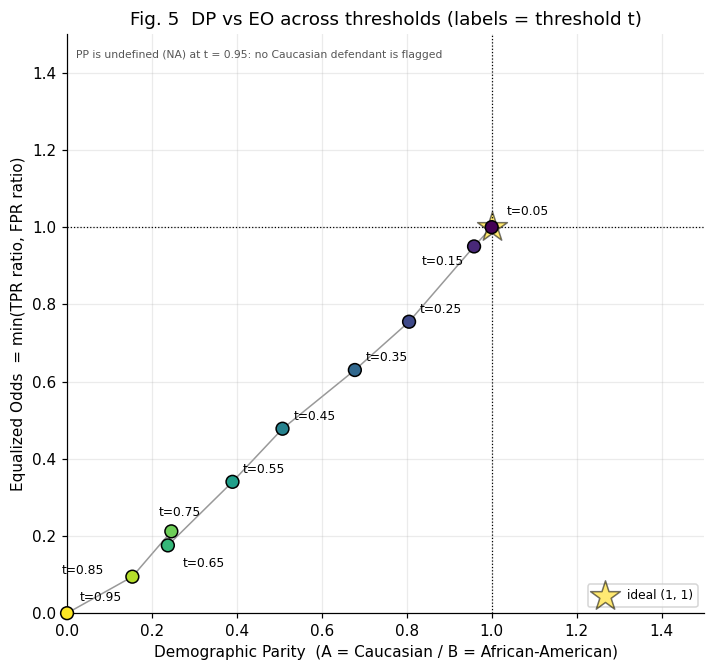

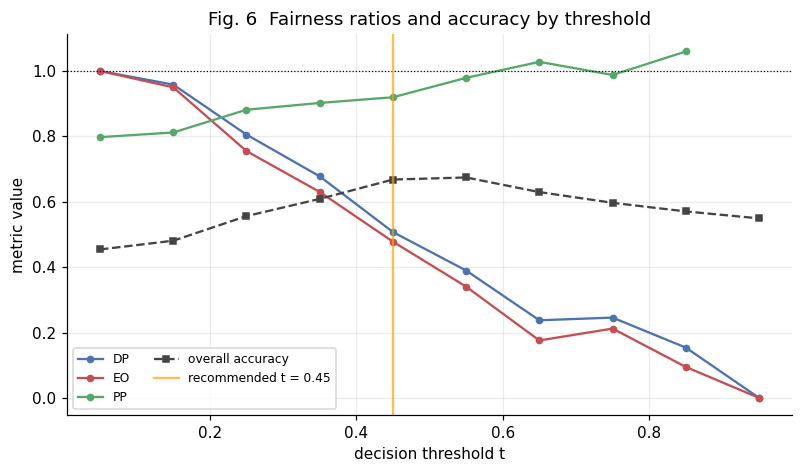

In [14]:
# ---- parity scores, trade-off quantification and threshold recommendation ----
def parity(m):  # orientation-free score in [0,1]: 1 = perfect parity
    return np.where(np.isnan(m), np.nan, np.minimum(m, 1 / np.where(m == 0, np.nan, m)).clip(max=1)) * 1.0
fs["s_DP"], fs["s_EO"], fs["s_PP"] = [np.nan_to_num(parity(fs[c].values), nan=np.nan) for c in ["DP", "EO", "PP"]]
fs.loc[fs.DP == 0, "s_DP"] = 0.0; fs.loc[fs.EO == 0, "s_EO"] = 0.0
fs["worst_parity"] = fs[["s_DP", "s_EO", "s_PP"]].min(axis=1, skipna=False)

def pct(a, b): return 100 * (b - a) / a
def tradeoff(t_from, t_to):
    a, b = fs.set_index("t").loc[t_from], fs.set_index("t").loc[t_to]
    dp_gain, eo_gain, pp_chg = pct(a.s_DP, b.s_DP), pct(a.s_EO, b.s_EO), pct(a.s_PP, b.s_PP)
    return {"t_from": t_from, "t_to": t_to, "DP_from": a.DP, "DP_to": b.DP, "EO_from": a.EO, "EO_to": b.EO, "PP_from": a.PP, "PP_to": b.PP,
            "DP_gain_pct": dp_gain, "EO_gain_pct": eo_gain, "PP_change_pct": pp_chg, "acc_from": a.acc_all, "acc_to": b.acc_all,
            "acc_change_pts": 100 * (b.acc_all - a.acc_all), "cost_PP_per_DP": (abs(pp_chg) / dp_gain) if dp_gain else np.nan,
            "cost_acc_pts_per_DP_pct": (abs(100 * (b.acc_all - a.acc_all)) / dp_gain) if dp_gain else np.nan}

# DP-vs-EO relationship across the sweep
ok = fs.dropna(subset=["DP", "EO"])
r_dp_eo = float(np.corrcoef(ok.DP, ok.EO)[0, 1])
consec = pd.DataFrame([tradeoff(fs.t[i + 1], fs.t[i]) for i in range(len(fs) - 1)])   # step DOWN in threshold
save_table(consec.round(5), "part24_consecutive_tradeoffs", index=False)
# any consecutive step where DP improves while EO worsens (a true DP-vs-EO trade-off)?
dp_up_eo_down = consec[(consec.DP_gain_pct > 0) & (consec.EO_gain_pct < 0)]

# --- transparent decision rule: highest worst-case parity among thresholds within `tol` accuracy points of the best accuracy ---
def choose(tol):
    elig = fs[fs.acc_all >= fs.acc_all.max() - tol].dropna(subset=["worst_parity"])
    return float(elig.loc[elig.worst_parity.idxmax(), "t"])
tols = {tol: choose(tol) for tol in [.01, .02, .03, .05, .07, .10, .20]}
T_STAR = tols[.02]
t_best_acc = float(fs.loc[fs.acc_all.idxmax(), "t"])
star = fs.set_index("t").loc[T_STAR]; star_ci = ci.set_index("t").loc[T_STAR]
print("tolerance -> threshold:", tols); print("accuracy-maximising t:", t_best_acc, " recommended t*:", T_STAR, " corr(DP,EO) =", round(r_dp_eo, 4))
print("steps where DP up & EO down:", len(dp_up_eo_down))
pairs = {"acc_max_to_star": tradeoff(t_best_acc, T_STAR), "star_to_lower": tradeoff(T_STAR, round(T_STAR - .10, 2)),
         "acc_max_to_0.25": tradeoff(t_best_acc, 0.25), "acc_max_to_0.05": tradeoff(t_best_acc, 0.05)}
display(pd.DataFrame(pairs).T.round(3))

# group-specific numbers at t*
yhat_s = (p_arr >= T_STAR).astype(int)
R["p24"] = {"A": "Caucasian", "B": "African-American", "n_A": int(A_mask.sum()), "n_B": int(B_mask.sum()),
            "base_rate_A": float(y_arr[A_mask].mean()), "base_rate_B": float(y_arr[B_mask].mean()),
            "mean_p_A": float(p_arr[A_mask].mean()), "mean_p_B": float(p_arr[B_mask].mean()),
            "thresholds": [float(t) for t in THRESHOLDS], "sweep": fs.round(6).where(fs.notna(), None).to_dict("records"),
            "ci": ci.round(5).where(ci.notna(), None).to_dict("records"), "alt_sweep": fs_alt.round(6).where(fs_alt.notna(), None).to_dict("records"),
            "corr_DP_EO": r_dp_eo, "n_steps_DP_up_EO_down": int(len(dp_up_eo_down)), "tol_to_threshold": {str(k): v for k, v in tols.items()},
            "t_star": T_STAR, "t_best_acc": t_best_acc, "star": {k: (None if (isinstance(v, float) and np.isnan(v)) else float(v)) for k, v in star.items()},
            "star_ci": {k: (None if np.isnan(v) else float(v)) for k, v in star_ci.items()},
            "pairs": {k: {kk: (None if (isinstance(vv, float) and np.isnan(vv)) else float(vv)) for kk, vv in v.items()} for k, v in pairs.items()},
            "na_cells": int(fs[["DP", "EO", "PP"]].isna().sum().sum()),
            "na_thresholds": [float(t) for t in fs.loc[fs[["DP", "EO", "PP"]].isna().any(axis=1), "t"]],
            "n_pos_A": int((y_arr[A_mask] == 1).sum()), "n_pos_B": int((y_arr[B_mask] == 1).sum()),
            "n_neg_A": int((y_arr[A_mask] == 0).sum()), "n_neg_B": int((y_arr[B_mask] == 0).sum()),
            "fp_A_at_star": int(((yhat_s == 1) & (y_arr == 0) & A_mask).sum()), "fp_B_at_star": int(((yhat_s == 1) & (y_arr == 0) & B_mask).sum()),
            "priors_mean_A": float(test_df.priors_count[A_mask].mean()), "priors_mean_B": float(test_df.priors_count[B_mask].mean()),
            "age_mean_A": float(test_df.age[A_mask].mean()), "age_mean_B": float(test_df.age[B_mask].mean())}

# ---- illustrative (hypothetical) profiles: identical records, different race, same fitted Model B ----
ill = []
for lab, age_, pri_ in [("30-year-old man, 3 priors, felony charge, no juvenile record", 30, 3), ("45-year-old man, 1 prior, felony charge, no juvenile record", 45, 1)]:
    for race_lab, aa in [("African-American", 1), ("Caucasian", 0)]:
        row = {"age": age_, "priors_count": pri_, "juv_fel_count": 0, "juv_misd_count": 0, "juv_other_count": 0, "male": 1, "felony": 1,
               "race_African_American": aa, "race_Hispanic": 0, "race_Other": 0}
        p_ = float(logit.predict(design(pd.DataFrame([row])))[0])
        ill.append({"profile": lab, "race": race_lab, "p": p_})
R["p24"]["illustration"] = ill; display(pd.DataFrame(ill).round(3))

# ---- required scatter plot: DP on x (0-1.5), EO on y (0-1.5), points labelled by threshold ----
fig, ax = plt.subplots(figsize=(6.6, 6.2))
okp = fs.dropna(subset=["DP", "EO"])
ax.scatter([1], [1], marker="*", s=420, c="gold", edgecolor="k", zorder=2, alpha=.55, label="ideal (1, 1)")
ax.plot(okp.DP, okp.EO, "-", color="#999999", lw=1, zorder=1)
ax.scatter(okp.DP, okp.EO, s=70, c=okp.t, cmap="viridis", edgecolor="k", zorder=3, clip_on=False)
offsets = {0.05: (10, 8), 0.15: (-34, -12), 0.95: (8, 8), 0.65: (10, -14), 0.75: (-8, 10), 0.85: (-46, 2)}
for _, r in okp.iterrows(): ax.annotate(f"t={r.t:.2f}", (r.DP, r.EO), textcoords="offset points", xytext=offsets.get(round(r.t, 2), (7, 6)), fontsize=8, zorder=5)
ax.axvline(1, color="k", ls=":", lw=.8); ax.axhline(1, color="k", ls=":", lw=.8)
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel("Demographic Parity  (A = Caucasian / B = African-American)"); ax.set_ylabel("Equalized Odds  = min(TPR ratio, FPR ratio)")
ax.set_title("Fig. 5  DP vs EO across thresholds (labels = threshold t)"); ax.legend(loc="lower right", fontsize=8)
ax.text(.02, 1.46, "PP is undefined (NA) at t = 0.95: no Caucasian defendant is flagged", fontsize=7, va="top", color="#555555")
plt.tight_layout(); plt.savefig(FIG / "fig5_dp_eo_tradeoff.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7.4, 4.4))
for c, col in [("DP", "#4C72B0"), ("EO", "#C44E52"), ("PP", "#55A868")]: ax.plot(fs.t, fs[c], "o-", color=col, label=c, ms=4)
ax.plot(fs.t, fs.acc_all, "s--", color="#444444", label="overall accuracy", ms=4); ax.axhline(1, color="k", ls=":", lw=.8)
ax.axvline(T_STAR, color="orange", lw=1.5, alpha=.7, label=f"recommended t = {T_STAR:.2f}")
ax.set_xlabel("decision threshold t"); ax.set_ylabel("metric value"); ax.set_title("Fig. 6  Fairness ratios and accuracy by threshold"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "fig6_metrics_by_threshold.png", dpi=200); plt.show()

## 11 · Robustness checks
Three sensitivity checks on the main Model B: (a) alternative target `is_recid`; (b) winsorising `priors_count` at the training 99th percentile; (c) a "race-blind" model without race indicators – to see whether removing the protected attribute removes the disparity (proxy effect).

In [15]:
def eval_variant(name, Xa, Xb, ya, yb, drop_cols=()):
    m = fit_logit(Xa, ya); p = m.predict(Xb)
    out = {"AUC": roc_auc_score(yb, p), "Accuracy@0.5": accuracy_score(yb, p >= .5), "Brier": brier_score_loss(yb, p)}
    r = fairness_row(yb.values, p.values, A_mask, B_mask, T_STAR)
    out.update({f"DP@{T_STAR}": r["DP"], f"EO@{T_STAR}": r["EO"], f"PP@{T_STAR}": r["PP"]})
    return name, out

rows = [eval_variant("Main model B (target two_year_recid)", Xtr, Xte, ytr, yte)]
rows.append(eval_variant("Target = is_recid", Xtr, Xte, train_df.is_recid, test_df.is_recid))
cap = float(train_df.priors_count.quantile(.99))
tr_w, te_w = train_df.assign(priors_count=train_df.priors_count.clip(upper=cap)), test_df.assign(priors_count=test_df.priors_count.clip(upper=cap))
sc_w = StandardScaler().fit(tr_w[CONT])
def design_w(d):
    Z = pd.DataFrame(sc_w.transform(d[CONT]), index=d.index, columns=CONT); X = pd.concat([Z, d[BIN].astype(float)], axis=1); X.insert(0, "const", 1.0); return X
rows.append(eval_variant(f"Priors winsorised at train p99 ({cap:.0f})", design_w(tr_w), design_w(te_w), ytr, yte))
rows.append(eval_variant("Race-blind (no race indicators)", Xtr.drop(columns=RACE_DUMMIES), Xte.drop(columns=RACE_DUMMIES), ytr, yte))
robust = pd.DataFrame(dict(rows)).T; save_table(robust.round(4), "robustness_checks"); display(robust.round(3))
R["robust"] = robust.round(5).to_dict("index"); R["robust"]["winsor_cap"] = cap

,AUC,Accuracy@0.5,Brier,DP@0.45,EO@0.45,PP@0.45
Main model B (target two_year_recid),0.734,0.679,0.208,0.507,0.478,0.920
Target = is_recid,0.740,0.680,0.208,0.544,0.519,0.886
Priors winsorised at train p99 (22),0.735,0.678,0.208,0.509,0.478,0.921
Race-blind (no race indicators),0.735,0.684,0.208,0.570,0.573,0.886


## 12 · Export and summary of computed findings

In [16]:
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if (np.isnan(o) or np.isinf(o)) else float(o)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    return o
(RES / "results.json").write_text(json.dumps(_clean(R), indent=1))

P1, M = R["part1"], R["p24"]
print("=== SUMMARY OF COMPUTED FINDINGS (seed 450, 70/30 split) ===")
print(f"Data: COMPAS, n={R['data']['n_rows']}  train={R['split']['n_train']}  test={R['split']['n_test']}  base rate={R['eda']['base_rate']:.3f}")
print(f"Model A test R2={R['modelA']['r2_test']:.3f}; median prediction={P1['median_pred_A']:.3f}; Model B acc={R['modelB']['accuracy']:.3f}, AUC={R['modelB']['auc']:.3f}")
print(f"Part 1: mismatches {P1['mismatch_n']} / {P1['n_test']} = {P1['mismatch_pct']:.2f}%  (A-high/B-low {P1['AhBl']}, A-low/B-high {P1['AlBh']})")
print(f"2.1: {R['p21_scan']['n_tests']} scanned tests, {R['p21_scan']['n_sign_flips']} sign flips, {R['p21_scan']['sign_flips_with_both_sig']} with both CIs excluding 0, {R['p21_scan']['n_sig_diff_bonferroni']} significant after Bonferroni")
print(f"2.2: dropped priors_count; largest % change = {R['p22']['largest_pct']}; largest absolute = {R['p22']['largest_abs']}")
print(f"2.3: {R['p23']['n_qualifying']} qualifying errors ({R['p23']['pct_of_test']:.2f}% of test); subset = {R['p23']['n_subset']}")
print(f"2.4: recommended t* = {M['t_star']}  DP={M['star']['DP']:.3f} EO={M['star']['EO']:.3f} PP={M['star']['PP']:.3f} acc={M['star']['acc_all']:.3f}; corr(DP,EO)={M['corr_DP_EO']:.3f}")
print("Saved:", sorted(p.name for p in TAB.glob('*.csv'))[:3], "... and", len(list(FIG.glob('*.png'))), "figures")

=== SUMMARY OF COMPUTED FINDINGS (seed 450, 70/30 split) ===
Data: COMPAS, n=7214  train=5049  test=2165  base rate=0.451
Model A test R2=0.422; median prediction=4.592; Model B acc=0.679, AUC=0.734
Part 1: mismatches 296 / 2165 = 13.67%  (A-high/B-low 283, A-low/B-high 13)
2.1: 26 scanned tests, 5 sign flips, 0 with both CIs excluding 0, 3 significant after Bonferroni
2.2: dropped priors_count; largest % change = juv_misd_count; largest absolute = age
2.3: 90 qualifying errors (4.16% of test); subset = 50
2.4: recommended t* = 0.45  DP=0.507 EO=0.478 PP=0.920 acc=0.668; corr(DP,EO)=0.998
Saved: ['descriptives.csv', 'eda_by_race.csv', 'eda_by_sex.csv'] ... and 6 figures


In [17]:
# Optional: rebuild the PDF from the saved results (requires `reportlab`; the analysis above does not).
import importlib.util, subprocess
if importlib.util.find_spec("reportlab") and (ROOT / "src" / "build_report.py").exists():
    print(subprocess.run([sys.executable, str(ROOT / "src" / "build_report.py")], capture_output=True, text=True, cwd=ROOT).stdout[-400:])
else:
    print("reportlab not installed or src/build_report.py missing -> skipped PDF rebuild (analysis outputs are complete).")

Wrote /home/claude/repo/report/CSET485_Assignment1_Report.pdf  (1035 KB)

